# Modelo GJR-GARCH: Entrenamiento y Evaluación

In [16]:
import warnings
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.models.gjr_garch_wrapper import GJRGARCHWrapper
from src.eval.scorer import VolatilityScorer
from src.trainer.walk_forward import WalkForwardTrainer

from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch, lilliefors
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import bds

from src.utils import trainer_toolkit as tt
from src.utils import test_toolkit as tk

warnings.filterwarnings("ignore")

OUT_PATH = PROJECT_ROOT / "data" / "processed"
RESULTS_PATH = PROJECT_ROOT / "results" / "gjr_garch"
MODELS_PATH = PROJECT_ROOT / "models"

RESULTS_PATH.mkdir(parents=True, exist_ok=True)
MODELS_PATH.mkdir(parents=True, exist_ok=True)

df_train = pd.read_parquet(OUT_PATH / "brent_train.parquet")
y_train = df_train["log_returns"].values.astype("float64")
rs_train = df_train["rs_daily"].values.astype("float64")

df_test = pd.read_parquet(OUT_PATH / "brent_test.parquet")
y_test = df_test["log_returns"].values.astype("float64")
rs_test = df_test["rs_daily"].values.astype("float64")

print(f"Train: {len(y_train)} obs ({df_train.index[0].date()} → {df_train.index[-1].date()})")
print(f"Test:  {len(y_test)} obs ({df_test.index[0].date()} → {df_test.index[-1].date()})")
print(f"Resultados de tablas y gráficas: {RESULTS_PATH}")
print(f"Modelos entrenados (.joblib):    {MODELS_PATH}")

Train: 2171 obs (2014-01-03 → 2022-11-03)
Test:  953 obs (2022-11-07 → 2026-08-21)
Resultados de tablas y gráficas: C:\Users\USER\Desktop\brent-crude-nlp-market-dynamics\results\gjr_garch
Modelos entrenados (.joblib):    C:\Users\USER\Desktop\brent-crude-nlp-market-dynamics\models


In [10]:
RESULTS_PATH = PROJECT_ROOT / "results" / "gjr_garch_final"

for exec_id in range(1, 6):
    archivos = [
        RESULTS_PATH_CORREGIDO / f"exec_{exec_id}" / f"grid_{grid_id}" / "results.csv"
        for grid_id in (1, 2)
    ]

    df_exec = pd.concat(
        [pd.read_csv(archivo) for archivo in archivos],
        ignore_index=True
    )

    exec_dir = RESULTS_PATH / f"exec_{exec_id}"
    exec_dir.mkdir(parents=True, exist_ok=True)

    df_exec.to_csv(exec_dir / "results.csv", index=False)

    print(f"Réplica {exec_id}: {len(df_exec)} evaluaciones consolidadas")

Réplica 1: 90 evaluaciones consolidadas
Réplica 2: 90 evaluaciones consolidadas
Réplica 3: 90 evaluaciones consolidadas
Réplica 4: 90 evaluaciones consolidadas
Réplica 5: 90 evaluaciones consolidadas


In [22]:
RESULTS_PATH = PROJECT_ROOT / "results" / "gjr_garch_final"

print("Ruta actual:", RESULTS_PATH.resolve())

Ruta actual: C:\Users\USER\Desktop\brent-crude-nlp-market-dynamics\results\gjr_garch_final


## Introducción

Para modelar la dinámica de la volatilidad en series financieras como el crudo Brent, Lawrence R. Glosten, Ravi Jagannathan y David E. Runkle (1993) propusieron el modelo GJR-GARCH como una extensión del modelo GARCH desarrollado por Bollerslev (1986). Esta formulación incorpora la posibilidad de que los choques positivos y negativos tengan efectos diferentes sobre la varianza condicional, permitiendo representar comportamientos asimétricos que los modelos ARCH y GARCH tradicionales no contemplan.

Esta libreta tiene como propósito presentar, entrenar y evaluar el comportamiento empírico del modelo GJR-GARCH sobre los retornos logarítmicos diarios del petróleo Brent. Su implementación permite estudiar la persistencia de la volatilidad, la influencia de las innovaciones pasadas y la posible existencia de respuestas asimétricas ante fluctuaciones del mercado.

### Modelo GJR-GARCH

La varianza condicional se modela mediante la formulación GJR-GARCH de órdenes $(p,o,q)$:

$$
\sigma_t^2 = \omega + \sum_{i=1}^{p}\alpha_i\varepsilon_{t-i}^2 + \sum_{j=1}^{o}\gamma_j\varepsilon_{t-j}^2 I(\varepsilon_{t-j}<0) + \sum_{k=1}^{q}\beta_k\sigma_{t-k}^2
$$

donde $\omega>0$ representa el nivel basal de varianza, los coeficientes $\alpha_i$ cuantifican la influencia de las innovaciones pasadas y los parámetros $\beta_k$ capturan la persistencia de la varianza condicional. Los coeficientes $\gamma_j$ incorporan el efecto asimétrico de las innovaciones negativas.

La función indicadora $I(\varepsilon_{t-j}<0)$ toma el valor de 1 cuando la innovación pasada es negativa y 0 en caso contrario. De esta manera, un choque negativo puede producir un incremento de volatilidad diferente al generado por un choque positivo de igual magnitud. Cuando $\gamma_j>0$, el efecto adicional de las innovaciones negativas es positivo, mientras que $\gamma_j=0$ implica la ausencia de dicho efecto para el rezago correspondiente.

Para garantizar que la varianza condicional permanezca no negativa, se requieren restricciones sobre los parámetros, entre ellas $\omega>0$, $\alpha_i\geq0$, $\beta_k\geq0$ y condiciones que aseguren una contribución no negativa de los términos asimétricos.

Bajo innovaciones estandarizadas simétricas, la condición habitual de estacionariedad en covarianza se expresa como:

$$
\sum_{i=1}^{p}\alpha_i + \frac{1}{2}\sum_{j=1}^{o}\gamma_j + \sum_{k=1}^{q}\beta_k < 1
$$

Esta condición establece que el efecto acumulado de las innovaciones y de la varianza pasada debe ser inferior a la unidad. Cuando se satisface, los choques sobre la volatilidad tienden a disiparse con el tiempo, permitiendo que la varianza condicional retorne hacia su nivel de largo plazo. Bajo estos supuestos, la varianza incondicional viene dada por:

$$
\mathbb{E}[\sigma_t^2] = \frac{\omega}{1-\sum_{i=1}^{p}\alpha_i-\frac{1}{2}\sum_{j=1}^{o}\gamma_j-\sum_{k=1}^{q}\beta_k}
$$

La implementación computacional del modelo GJR-GARCH se realiza mediante la librería `arch` de Python, utilizando la parametrización de varianza asimétrica con potencia igual a 2.

## Diseño Experimental

### Entrenamiento y Validación Cruzada

El ajuste de los modelos y la búsqueda de hiperparámetros se realizan mediante un esquema de validación cruzada de ventana expansiva (*walk-forward validation*). A diferencia de la validación cruzada tradicional, este procedimiento respeta la dependencia temporal de los datos: el conjunto de entrenamiento se expande progresivamente, mientras que el conjunto de validación corresponde al bloque temporal inmediatamente posterior.

Para garantizar un tamaño muestral mínimo, se establece un periodo inicial de calentamiento (*warm-up*). Posteriormente, los datos se dividen en 5 pliegues cronológicos. En cada iteración, el modelo se estima sobre el bloque de entrenamiento y se evalúa mediante la pérdida QLIKE sobre el bloque de validación.

La búsqueda de hiperparámetros considera los órdenes $p\in\{1,2\}$, $o\in\{1,2\}$ y $q\in\{1,2\}$, junto con tres distribuciones para las innovaciones estandarizadas: Normal, Student-$t$ y GED. Esto produce un total de 24 configuraciones candidatas, evaluadas bajo el mismo esquema temporal.

## Entrenamiento

Para identificar la configuración óptima del modelo GJR-GARCH, se realizaron cinco iteraciones independientes del esquema de validación cruzada definido previamente. En cada iteración, se evaluaron distintas combinaciones de los órdenes \(p\), \(o\) y \(q\), que representan los componentes ARCH, asimétrico y GARCH, respectivamente. Este procedimiento permitió explorar diferentes estructuras de dependencia temporal y capturar posibles respuestas asimétricas de la volatilidad ante perturbaciones positivas y negativas.

In [6]:
scorer = VolatilityScorer()

RESULTS_PATH_CORREGIDO = PROJECT_ROOT / "results" / "gjr_garch_corregido_v2"

param_grids = [
    {
        "p": [1],
        "o": [1],
        "q": [1, 2],
        "dist": ["normal", "t", "ged"]
    },
    {
        "p": [2],
        "o": [1, 2],
        "q": [1, 2],
        "dist": ["normal", "t", "ged"]
    }
]

for exec_id in range(1, 6):
    current_warmup = 1200 + (exec_id * 10)

    for grid_id, param_grid in enumerate(param_grids, start=1):
        exec_dir = (
            RESULTS_PATH_CORREGIDO
            / f"exec_{exec_id}"
            / f"grid_{grid_id}"
        )

        exec_dir.mkdir(parents=True, exist_ok=True)

        trainer = WalkForwardTrainer(
            model_class=GJRGARCHWrapper,
            param_grid=param_grid,
            scorer=scorer,
            output_dir=exec_dir,
            n_splits=5,
            warmup=current_warmup
        )

        trainer.run(y_train, rs_train)

Grid Search:  33%|███▎      | 4/12 [00:00<00:01,  6.66config/s, params={'dist': 't', 'o': 1, 'p': 2, 'q': 1}]     C:\Users\USER\Desktop\brent-crude-nlp-market-dynamics\src\models\gjr_garch_wrapper.py:117: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  self.model_fit = am.fit(disp="off")
Grid Search:  67%|██████▋   | 8/12 [00:01<00:00,  6.11config/s, params={'dist': 'ged', 'o': 1, 'p': 2, 'q': 1}]C:\Users\USER\Desktop\brent-crude-nlp-market-dynamics\src\models\gjr_garch_wrapper.py:117: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  self.model_fit = am.fit(disp="off")
Grid Search: 100%|██████████| 12/12 [00:02<00:00,  5.94config/s, params={'dist': 'ged', 'o': 2, 'p': 2, 'q': 2}]


In [24]:
tt.display_top_results(
    RESULTS_PATH,
    top_n=5,
    aggregate_mode="mean",
    column_names=(
        "Distribución", "Orden (p)", "Orden (o)", "Orden (q)",
        "Réplica 1", "Réplica 2", "Réplica 3", "Réplica 4", "Réplica 5",
        "Global (Media ± SD)"
    )
)

Distribución,Orden (p),Orden (o),Orden (q),Réplica 1,Réplica 2,Réplica 3,Réplica 4,Réplica 5,Global (Media ± SD)
t,1,1,2,0.469 ± 0.140,0.463 ± 0.142,0.454 ± 0.116,0.454 ± 0.114,0.470 ± 0.132,0.462 ± 0.008
normal,1,1,1,0.474 ± 0.148,0.458 ± 0.132,0.457 ± 0.132,0.467 ± 0.133,0.459 ± 0.113,0.463 ± 0.007
t,1,1,1,0.528 ± 0.240,0.454 ± 0.130,0.451 ± 0.122,0.458 ± 0.119,0.457 ± 0.117,0.470 ± 0.033
ged,1,1,1,0.527 ± 0.241,0.458 ± 0.133,0.447 ± 0.120,0.457 ± 0.120,0.464 ± 0.117,0.471 ± 0.032
ged,1,1,2,0.473 ± 0.153,0.471 ± 0.157,0.470 ± 0.148,0.474 ± 0.147,0.479 ± 0.147,0.473 ± 0.004


Los resultados del grid search corregido del modelo GJR-GARCH muestran que la configuración (1,1,2) con distribución t de Student obtuvo el menor QLIKE promedio global (0.462 ± 0.008), seguida del modelo (1,1,1) con distribución normal (0.463 ± 0.007). Ambas configuraciones presentan un desempeño predictivo similar y una baja variabilidad entre las cinco réplicas. Por su parte, las distribuciones t de Student y GED con orden (1,1,1) registraron valores de 0.470 ± 0.033 y 0.471 ± 0.032, respectivamente. Bajo el criterio de QLIKE promedio, la configuración (1,1,2) con distribución t de Student presenta el mejor desempeño.

In [12]:
tt.display_top_results(
    RESULTS_PATH,
    top_n=5,
    aggregate_mode="median",
    column_names=(
        "Distribución",
        "Orden (p)",
        "Orden (o)",
        "Orden (q)",
        "Réplica 1", "Réplica 2", "Réplica 3", "Réplica 4", "Réplica 5",
        "Global (Mediana ± IQR)"
    )
)

Distribución,Orden (p),Orden (o),Orden (q),Réplica 1,Réplica 2,Réplica 3,Réplica 4,Réplica 5,Global (Mediana ± IQR)
t,2,2,1,0.503 ± 0.229,0.518 ± 0.193,0.468 ± 0.153,0.462 ± 0.157,0.448 ± 0.139,0.468 ± 0.041
t,1,1,2,0.512 ± 0.170,0.477 ± 0.162,0.476 ± 0.079,0.472 ± 0.080,0.445 ± 0.066,0.476 ± 0.005
ged,1,1,2,0.514 ± 0.168,0.477 ± 0.172,0.476 ± 0.079,0.480 ± 0.075,0.463 ± 0.072,0.477 ± 0.004
normal,1,1,2,0.508 ± 0.170,0.477 ± 0.158,0.481 ± 0.085,0.480 ± 0.088,0.463 ± 0.073,0.480 ± 0.005
normal,1,2,2,0.523 ± 0.184,0.496 ± 0.173,0.481 ± 0.101,0.480 ± 0.118,0.462 ± 0.120,0.481 ± 0.016


Los resultados del grid search corregido muestran que la configuración GJR-GARCH(2,2,1) con distribución t de Student obtuvo el menor QLIKE mediano global (0.468 ± 0.041), seguida de las configuraciones (1,1,2) con distribuciones t de Student (0.476 ± 0.005) y GED (0.477 ± 0.004). Aunque el modelo (2,2,1) presenta el mejor desempeño según la mediana, también registra una mayor variabilidad entre réplicas. Por su parte, las configuraciones (1,1,2) muestran resultados más estables. En consecuencia, el modelo GJR-GARCH(2,2,1) con distribución t de Student se posiciona como la mejor alternativa bajo el criterio de QLIKE mediano.

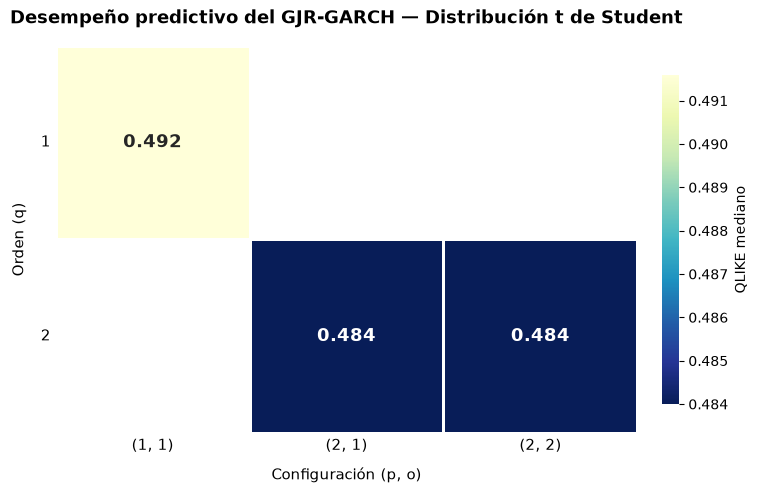

In [18]:
df_t = df_resultados[
    df_resultados["dist"] == "t"
].copy()

matriz_mediana = (
    df_t
    .groupby(["q", "p", "o"])["qlike"]
    .median()
    .unstack(["p", "o"])
)

matriz_mediana = matriz_mediana.reindex(
    index=[1, 2],
    columns=pd.MultiIndex.from_tuples([
        (1, 1),
        (2, 1),
        (2, 2)
    ])
)

matriz_mediana.columns = [
    f"({p}, {o})"
    for p, o in matriz_mediana.columns
]

fig, ax = plt.subplots(figsize=(9, 5))

sns.heatmap(
    matriz_mediana,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu_r",
    linewidths=2,
    linecolor="white",
    annot_kws={
        "fontsize": 13,
        "fontweight": "bold"
    },
    cbar_kws={
        "label": "QLIKE mediano",
        "shrink": 0.85,
        "pad": 0.03
    },
    square=True,
    ax=ax
)

ax.set_title(
    "Desempeño predictivo del GJR-GARCH — Distribución t de Student",
    fontsize=13,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Configuración (p, o)", fontsize=11, labelpad=10)
ax.set_ylabel("Orden (q)", fontsize=11, labelpad=10)

ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

ax.tick_params(axis="both", labelsize=11, length=0)

plt.tight_layout()
plt.show()

Para la distribución t de Student, la configuración GJR-GARCH(2,2,1) presenta el menor QLIKE mediano (0.468), seguida de la configuración (1,1,2), con un valor de 0.476. Por su parte, el modelo tradicional (1,1,1) registra una mediana de 0.492, lo que evidencia un mejor desempeño predictivo de las configuraciones anteriores. Sin embargo, aunque el modelo (2,2,1) obtiene el menor QLIKE mediano, la configuración (1,1,2) presenta un mejor desempeño promedio y mayor estabilidad entre réplicas, por lo que se selecciona como modelo definitivo.

In [23]:
tt.display_top_results(
    RESULTS_PATH,
    q_filter=[1, 2],
    aggregate_mode="median",
    column_names=(
        "Distribución",
        "Orden (p)",
        "Orden (o)",
        "Orden (q)",
        "Réplica 1", "Réplica 2", "Réplica 3", "Réplica 4", "Réplica 5",
        "Global (Mediana ± IQR)"
    )
)

Distribución,Orden (p),Orden (o),Orden (q),Réplica 1,Réplica 2,Réplica 3,Réplica 4,Réplica 5,Global (Mediana ± IQR)
t,2,2,1,0.503 ± 0.229,0.518 ± 0.193,0.468 ± 0.153,0.462 ± 0.157,0.448 ± 0.139,0.468 ± 0.041
t,1,1,2,0.512 ± 0.170,0.477 ± 0.162,0.476 ± 0.079,0.472 ± 0.080,0.445 ± 0.066,0.476 ± 0.005
ged,1,1,2,0.514 ± 0.168,0.477 ± 0.172,0.476 ± 0.079,0.480 ± 0.075,0.463 ± 0.072,0.477 ± 0.004
normal,1,1,2,0.508 ± 0.170,0.477 ± 0.158,0.481 ± 0.085,0.480 ± 0.088,0.463 ± 0.073,0.480 ± 0.005
normal,1,2,2,0.523 ± 0.184,0.496 ± 0.173,0.481 ± 0.101,0.480 ± 0.118,0.462 ± 0.120,0.481 ± 0.016


Los resultados muestran que la configuración GJR-GARCH(2,2,1) con distribución t de Student obtuvo el menor QLIKE mediano global (0.468), aunque presentó una mayor dispersión entre réplicas (IQR = 0.041). Le sigue la configuración (1,1,2), también con distribución t de Student, con una mediana de 0.476 y un IQR considerablemente menor (0.005). Las distribuciones GED y normal con orden (1,1,2) registraron valores ligeramente superiores, de 0.477 y 0.480, respectivamente. Aunque el modelo (2,2,1) alcanza la menor pérdida mediana, la configuración (1,1,2) combina un desempeño competitivo con mayor estabilidad entre réplicas, lo que respalda su selección como modelo definitivo.

In [25]:
best_model = GJRGARCHWrapper(params={"p": 1, "o": 1, "q": 2, "dist": "t"})
best_model.fit(y_train)

df_params_boot = best_model.get_parameter_table(
    B=2000,
    decimals=4,
    block_size=22
)

df_params_boot = df_params_boot.rename(columns={
    "Parameter": "Parámetro",
    "Coef": "Coeficiente",
    "Std. Error": "Error Estándar",
    "P-value": "p-valor",
    "CI Lower": "IC Inferior",
    "CI Upper": "IC Superior"
})

tt.display_styled_df(
    df=df_params_boot,
    decimals=4,
    p_value_cols=["p-valor"]
)

C:\Users\USER\Desktop\brent-crude-nlp-market-dynamics\src\models\gjr_garch_wrapper.py:391: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  res_boot = am_boot.fit(


Parámetro,Coeficiente,Error Estándar,p-valor,IC Inferior,IC Superior
omega,0.0000,0.0000,< .001,0.0000,0.0001
alpha[1],0.0607,0.0126,< .001,0.0500,0.2025
gamma[1],0.0754,0.0241,.002,-0.1064,0.1000
beta[1],0.7765,0.1541,< .001,0.2124,0.8780
beta[2],0.1171,0.1487,.431,0.0000,0.6407
nu,5.0348,0.5112,< .001,3.6216,5.9348


La estimación del GJR-GARCH(1,1,2) muestra un coeficiente ARCH significativo (α₁ = 0.0607; p < 0.001), lo que evidencia la influencia de los choques recientes sobre la volatilidad. El coeficiente de asimetría también resulta significativo según su valor p (γ₁ = 0.0754; p = 0.002), lo que sugiere una mayor respuesta de la volatilidad ante retornos negativos. Entre los componentes GARCH, β₁ = 0.7765 presenta significancia estadística, mientras que β₂ = 0.1171 no alcanza el nivel del 5%, indicando que la persistencia de la volatilidad se concentra principalmente en el primer rezago.

Por su parte, el parámetro ν = 5.0348 caracteriza una distribución t de Student con colas pesadas, apropiada para representar movimientos extremos en los retornos. Sin embargo, el intervalo de confianza de γ₁ incluye el cero, pese a su valor p significativo, por lo que la evidencia inferencial sobre el efecto asimétrico no es concluyente.

In [26]:
std_residuals = np.asarray(best_model.model_fit.std_resid, dtype=float)
std_residuals = std_residuals[np.isfinite(std_residuals)]

rows = []

lb_res = acorr_ljungbox(
    std_residuals,
    lags=[10, 20, 30],
    return_df=True
)

for lag in (10, 20, 30):
    rows.append({
        "Test": f"Ljung-Box (Lag {lag})",
        "Stat": lb_res.loc[lag, "lb_stat"],
        "p_raw": lb_res.loc[lag, "lb_pvalue"],
        "Family": "LB"
    })

for lag in (10, 20, 30):
    arch_stat, arch_p, _, _ = het_arch(std_residuals, nlags=lag)

    rows.append({
        "Test": f"ARCH-LM (Lag {lag})",
        "Stat": arch_stat,
        "p_raw": arch_p,
        "Family": "ARCH"
    })

jb_stat, jb_p = stats.jarque_bera(std_residuals)

rows.append({
    "Test": "Jarque-Bera",
    "Stat": jb_stat,
    "p_raw": jb_p,
    "Family": "Normality"
})

lf_stat, lf_p = lilliefors(
    std_residuals,
    dist="norm",
    pvalmethod="table"
)

rows.append({
    "Test": "Lilliefors",
    "Stat": lf_stat,
    "p_raw": lf_p,
    "Family": "Normality"
})

bds_stat, bds_p = bds(std_residuals, max_dim=2)

rows.append({
    "Test": "BDS (Dim 2)",
    "Stat": float(np.asarray(bds_stat).item()),
    "p_raw": float(np.asarray(bds_p).item()),
    "Family": "BDS"
})

df_diag = pd.DataFrame(rows)
df_diag["p_adj"] = np.nan

for fam in df_diag["Family"].unique():
    mask = df_diag["Family"] == fam
    p_values = df_diag.loc[mask, "p_raw"].to_numpy(dtype=float)

    if mask.sum() > 1:
        p_adj = multipletests(
            p_values,
            method="bonferroni"
        )[1]
    else:
        p_adj = p_values

    df_diag.loc[mask, "p_adj"] = np.asarray(p_adj, dtype=float)

conclusions = []

for _, row in df_diag.iterrows():
    p = row["p_adj"]
    test = row["Test"]

    if "Ljung-Box" in test:
        concl = "Sin Autocorrelación" if p > 0.05 else "Autocorrelación Significativa"
    elif "ARCH-LM" in test:
        concl = "Sin Efectos ARCH" if p > 0.05 else "Efectos ARCH Significativos"
    elif "BDS" in test:
        concl = "Sin Estructura No Lineal" if p > 0.05 else "Estructura No Lineal Significativa"
    else:
        concl = "Residuos Normales" if p > 0.05 else "Residuos No Normales"

    conclusions.append(concl)

df_diag["Conclusion"] = conclusions

df_diag = df_diag[
    ["Test", "Stat", "p_raw", "p_adj", "Conclusion"]
].copy()

df_diag.columns = [
    "Prueba Estadística",
    "Estadístico",
    "p-valor",
    "p-ajustado (Bonferroni)",
    "Conclusión (α = 0.05)"
]

tt.display_styled_df(
    df=df_diag,
    decimals=3,
    p_value_cols=["p-valor", "p-ajustado (Bonferroni)"]
)

Prueba Estadística,Estadístico,p-valor,p-ajustado (Bonferroni),Conclusión (α = 0.05)
Ljung-Box (Lag 10),7.286,.698,1.000,Sin Autocorrelación
Ljung-Box (Lag 20),24.803,.209,.627,Sin Autocorrelación
Ljung-Box (Lag 30),34.590,.258,.774,Sin Autocorrelación
ARCH-LM (Lag 10),3.641,.962,1.000,Sin Efectos ARCH
ARCH-LM (Lag 20),7.658,.994,1.000,Sin Efectos ARCH
ARCH-LM (Lag 30),16.820,.975,1.000,Sin Efectos ARCH
Jarque-Bera,1791.017,< .001,< .001,Residuos No Normales
Lilliefors,0.050,< .001,.002,Residuos No Normales
BDS (Dim 2),0.334,.738,.738,Sin Estructura No Lineal


Las pruebas de Ljung-Box y ARCH-LM muestran que el modelo GJR-GARCH(1,1,2) con distribución t de Student no presenta evidencia de autocorrelación ni de efectos ARCH residuales significativos en los rezagos evaluados, dado que todos los valores p ajustados superan el nivel de significancia de 0.05. Asimismo, la prueba BDS (p = 0.738) no identifica evidencia de dependencia no lineal remanente.

Por otra parte, las pruebas de Jarque-Bera y Lilliefors rechazan la hipótesis de normalidad de los residuos (p < 0.001 y p ajustado = 0.002, respectivamente). Este resultado es compatible con la presencia de colas pesadas y con la elección de una distribución t de Student. En conjunto, los diagnósticos indican que el modelo captura adecuadamente la dependencia temporal evaluada, aunque los residuos estandarizados mantienen una distribución alejada de la normalidad.

In [27]:
pred_vol_train = best_model.model_fit.conditional_volatility

tk.plot_volatility_fit(
    dates=df_train.index,
    rs=rs_train,
    pred_vol=pred_vol_train,
    title="Volatilidad Realizada vs Condicional — GJR-GARCH(1,1,2) (Entrenamiento)",
    legend_size=13,
    legend_loc="upper left"
)

El modelo GJR-GARCH(1,1,2) con distribución t de Student reproduce adecuadamente la dinámica general de la volatilidad durante el periodo de entrenamiento, identificando tanto las etapas de relativa estabilidad como los principales episodios de incremento del riesgo. Se observa una correspondencia entre la volatilidad realizada y la condicional estimada, especialmente durante los periodos de mayor turbulencia registrados entre 2015 y 2016, en 2020 y durante 2022.

El episodio de 2020 presenta las mayores fluctuaciones de toda la serie. Aunque el modelo identifica el aumento abrupto de la volatilidad y su posterior disminución, suaviza los picos más extremos y muestra una respuesta más persistente que la volatilidad realizada. Este comportamiento también se observa, en menor medida, en otros periodos de alta variabilidad. En general, el ajuste permite representar los cambios en el nivel de volatilidad, aunque presenta limitaciones para reproducir la magnitud de las fluctuaciones más pronunciadas.

## Registro de ejecuciones y evaluaciones fallidas

Durante la búsqueda de hiperparámetros del modelo GJR-GARCH se evaluaron 18 configuraciones mediante validación cruzada de cinco particiones y cinco réplicas, para un total de 450 evaluaciones. De estas, 448 finalizaron con métricas válidas (99.56 %), mientras que dos presentaron resultados faltantes. Ambas correspondieron a la configuración GJR-GARCH(2,1,1), específicamente con distribución t de Student en la tercera réplica y distribución GED en la quinta, en ambos casos durante el tercer fold de validación.

Los archivos de seguimiento registraron una evaluación fallida en cada una de estas ejecuciones, sin evidenciar fallos adicionales en las demás configuraciones. Asimismo, todas las combinaciones evaluadas cumplieron la restricción estructural $o \leq p$.

## Evaluación

In [28]:
scorer = VolatilityScorer()

q_context = best_model.context_length

predictions_test = best_model.forecast(
    y_target=y_test,
    initial_context=y_train[-q_context:]
)

tk.display_train_test_comparison(
    model=best_model,
    scorer=scorer,
    rs_train=rs_train,
    rs_test=rs_test,
    preds_test=predictions_test,
    dist="t",
    nu=best_model.model_fit.params["nu"],
    decimals=6,
    column_titles=(
        "Métrica",
        "Entrenamiento",
        "Prueba",
        "Diferencia"
    ),
    show_diff=True
)

Métrica,Entrenamiento,Prueba,Diferencia
QLIKE,0.382797,0.458161,+0.075364
MSE,0.000003,0.000005,+0.000002
RMSE,0.001796,0.002201,+0.000405
MAE,0.000475,0.000488,+0.000013
CRPS,0.004779,0.004604,-0.000175
Pinball (τ=0.05),0.001883,0.001802,-0.000081
Pinball (τ=0.95),0.001822,0.001758,-0.000063


El modelo GJR-GARCH(1,1,2) con distribución t de Student mantiene un desempeño predictivo relativamente estable fuera de muestra, aunque presenta un deterioro moderado en algunas métricas. El QLIKE aumenta de 0.382797 en entrenamiento a 0.458161 en prueba, mientras que el RMSE pasa de 0.001796 a 0.002201, lo que indica una mayor discrepancia entre la volatilidad estimada y la realizada. Sin embargo, el MAE apenas aumenta de 0.000475 a 0.000488, lo que sugiere que el error absoluto promedio se mantiene prácticamente constante. Por su parte, el CRPS y las pérdidas Pinball en ambos cuantiles presentan ligeras reducciones durante la evaluación fuera de muestra. En conjunto, los resultados evidencian una capacidad de generalización favorable, aunque con cierta pérdida de precisión según las métricas QLIKE y RMSE.

In [29]:
pred_vol_test = np.sqrt(predictions_test)

tk.plot_volatility_fit(
    dates=df_test.index,
    rs=rs_test,
    pred_vol=pred_vol_test,
    title="Volatilidad Realizada vs Condicional — GJR-GARCH(1,1,2) (Prueba)",
    legend_loc="upper left",
    legend_size=13
)

Durante el periodo de prueba, el modelo GJR-GARCH(1,1,2) con distribución t de Student reproduce la tendencia general de la volatilidad realizada, especialmente en los periodos de fluctuación moderada entre 2023 y 2025. Sin embargo, se observan diferencias durante los episodios de mayor inestabilidad, particularmente a comienzos de 2026, cuando la volatilidad realizada alcanza un pico cercano a 0.25, mientras que la volatilidad condicional estimada permanece por debajo de 0.10.

Aunque el modelo identifica el incremento de la volatilidad durante este episodio, subestima considerablemente su magnitud y mantiene niveles elevados durante más tiempo que la serie realizada. Este comportamiento es similar al observado durante el entrenamiento y evidencia una mayor capacidad para representar la dinámica general y la persistencia de la volatilidad que para capturar fluctuaciones extremas y repentinas.